1. Silakan upload file output_farmasi_parquet.zip dari komputer Anda:


Saving output_farmasi_parquet.zip to output_farmasi_parquet (2).zip
✅ File ZIP berhasil diekstrak ke folder: output_farmasi_parquet

2. Memulai Validasi Data dengan PySpark...
--- VALIDASI DATABASE ---
Jumlah baris terdeteksi: 100000 baris.
✅ Status: 100.000 Data Enterprise Utuh Tanpa Korupsi!

Menyiapkan visualisasi bisnis tingkat lanjut...


<Figure size 1500x700 with 0 Axes>

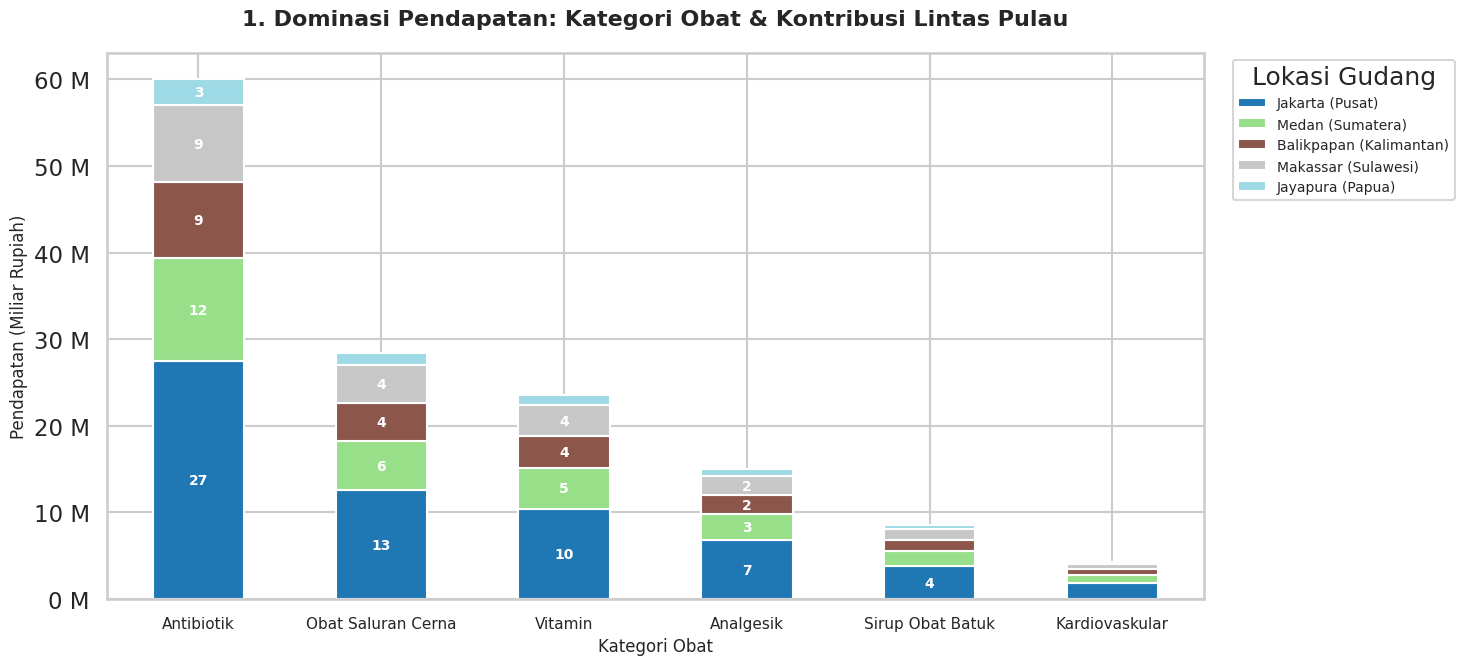

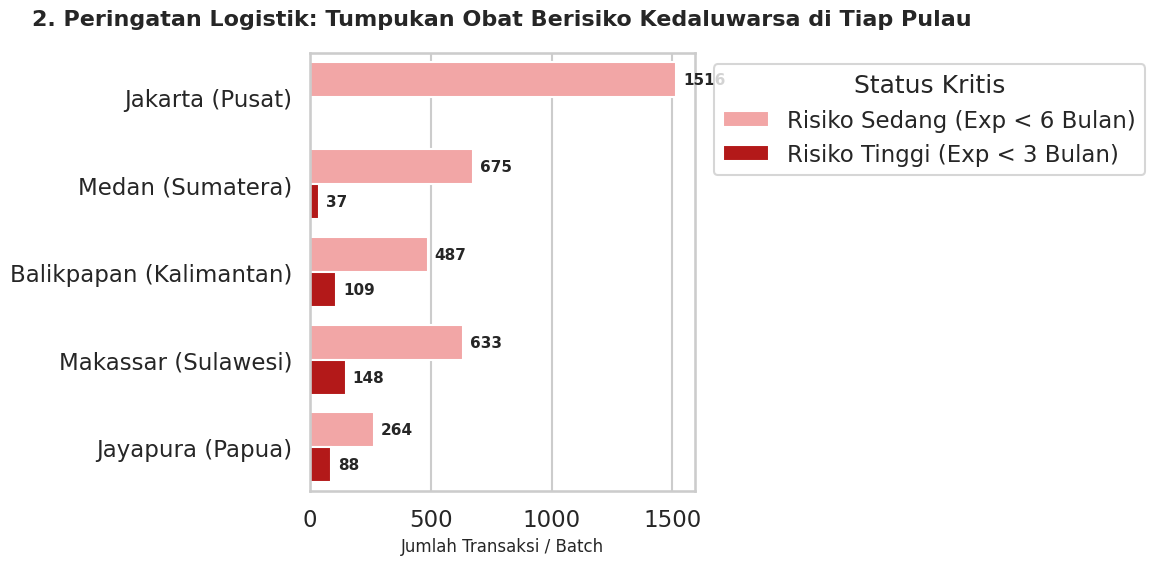

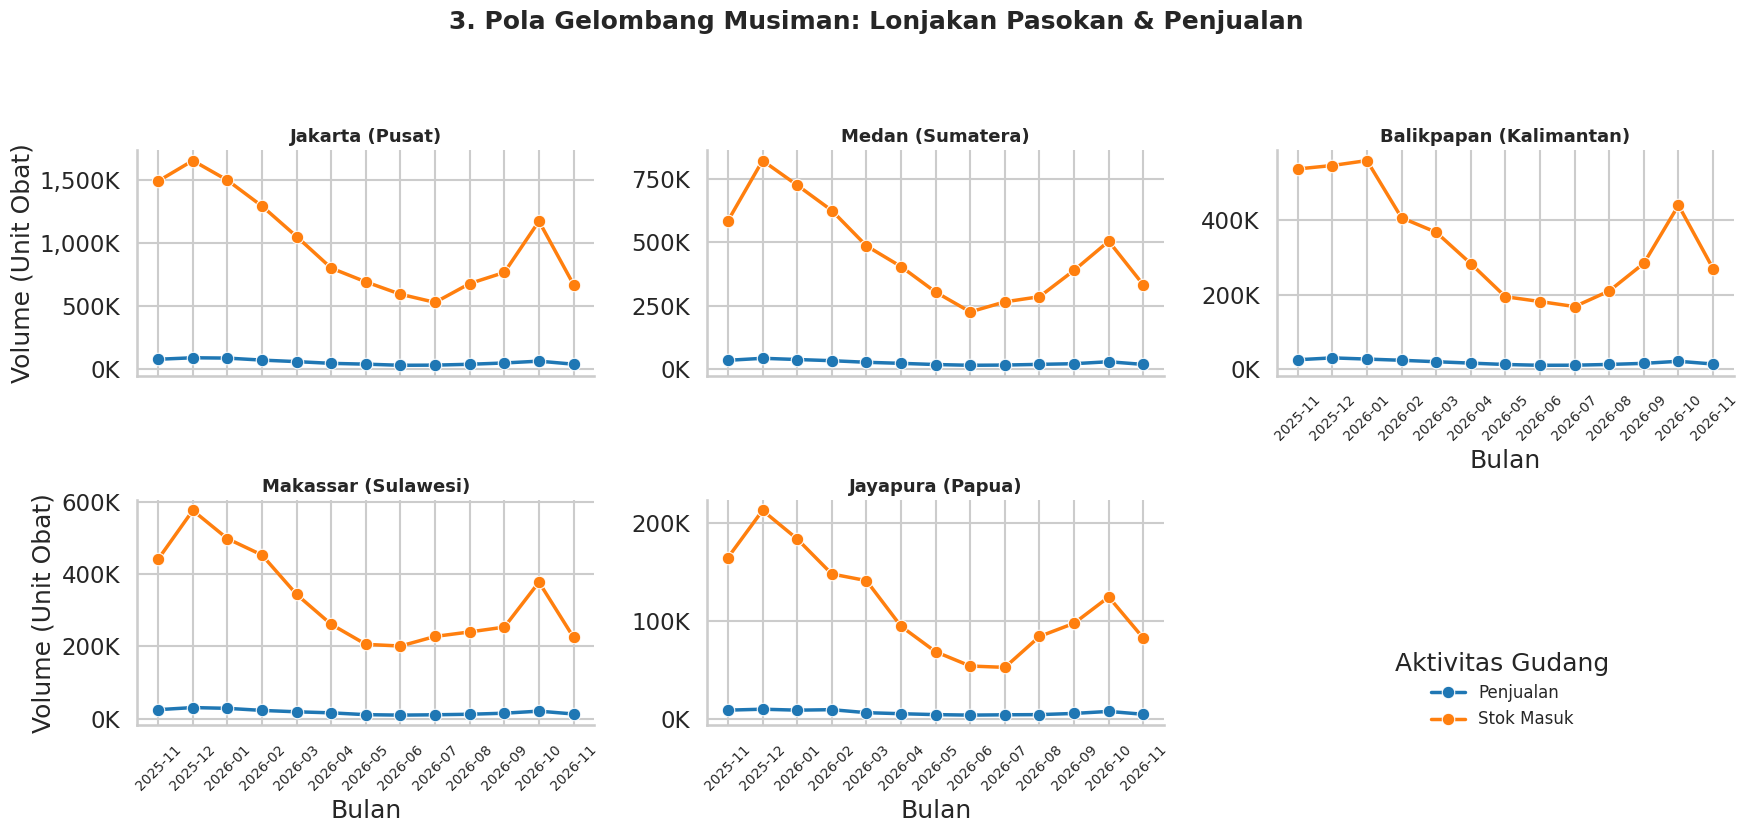

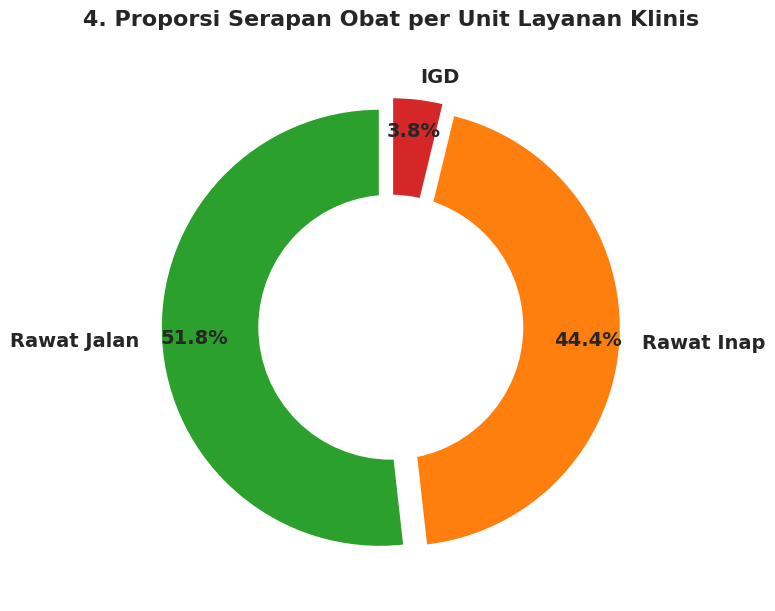

In [3]:
# ==========================================
# TAHAP 1: INSTALASI & PERSIAPAN FILE PARQUET
# ==========================================
import os
import zipfile

# Blok ini akan meminta upload JIKA Anda menggunakan Google Colab.
# Jika Anda di VS Code, blok ini akan dilewati otomatis tanpa error.
try:
    from google.colab import files
    print("1. Silakan upload file output_farmasi_parquet.zip dari komputer Anda:")
    uploaded = files.upload()
    zip_file_name = list(uploaded.keys())[0]
    extract_dir = "output_farmasi_parquet"
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print(f"✅ File ZIP berhasil diekstrak ke folder: {extract_dir}\n")
except ImportError:
    print("1. Berjalan di mode lokal (VS Code). Menggunakan folder Parquet yang sudah ada di laptop.\n")

# ==========================================
# TAHAP 2: VALIDASI PYSPARK & KONVERSI PANDAS
# ==========================================
# Pastikan Anda sudah menjalankan `pip install pyspark` jika di Colab/Lokal
from pyspark.sql import SparkSession
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

print("2. Memulai Validasi Data dengan PySpark...")
spark = SparkSession.builder.appName("Validasi_Enterprise").getOrCreate()
df_parquet = spark.read.parquet("output_farmasi_parquet")

total_baris = df_parquet.count()
print(f"--- VALIDASI DATABASE ---")
print(f"Jumlah baris terdeteksi: {total_baris} baris.")
if total_baris == 100000:
    print("✅ Status: 100.000 Data Enterprise Utuh Tanpa Korupsi!\n")
else:
    print("⚠️ Peringatan: Baris tidak berjumlah 100.000!")

print("Menyiapkan visualisasi bisnis tingkat lanjut...")
df_vis = df_parquet.toPandas()
df_vis['bulan_transaksi'] = pd.to_datetime(df_vis['transaction_date']).dt.to_period('M').astype(str)
sns.set_theme(style="whitegrid", context="talk")

urutan_gudang = ['Jakarta (Pusat)', 'Medan (Sumatera)', 'Balikpapan (Kalimantan)', 'Makassar (Sulawesi)', 'Jayapura (Papua)']

# ==========================================
# TAHAP 3: GRAFIK 1 - PENDAPATAN (STACKED BAR)
# ==========================================
plt.figure(figsize=(15, 7))
df_penjualan = df_vis[df_vis['transaction_type'] == 'Penjualan'].copy()
df_penjualan['total_value_miliar'] = df_penjualan['total_value'] / 1000000000

pendapatan = df_penjualan.pivot_table(
    index='product_category', columns='warehouse', values='total_value_miliar', aggfunc='sum'
).fillna(0)

pendapatan['Total'] = pendapatan.sum(axis=1)
pendapatan = pendapatan.sort_values(by='Total', ascending=False).drop(columns=['Total'])
pendapatan = pendapatan[[col for col in urutan_gudang if col in pendapatan.columns]]

ax1 = pendapatan.plot(kind='bar', stacked=True, colormap='tab20', figsize=(15, 7), edgecolor='white')
plt.title('1. Dominasi Pendapatan: Kategori Obat & Kontribusi Lintas Pulau', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Pendapatan (Miliar Rupiah)', fontsize=12)
plt.xlabel('Kategori Obat', fontsize=12)
plt.xticks(rotation=0, fontsize=11)

for c in ax1.containers:
    labels = [f'{v.get_height():.0f}' if v.get_height() > 2 else '' for v in c]
    ax1.bar_label(c, labels=labels, label_type='center', color='white', fontsize=10, fontweight='bold')

ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f} M'))
plt.legend(title='Lokasi Gudang', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

# ==========================================
# TAHAP 4: GRAFIK 2 - RISIKO KEDALUWARSA (HORIZONTAL BAR)
# ==========================================
plt.figure(figsize=(12, 6))
df_risk = df_vis[df_vis['expiry_risk_status'] != 'Aman']
color_dict = {'Risiko Sedang (Exp < 6 Bulan)': '#ff9999', 'Risiko Tinggi (Exp < 3 Bulan)': '#cc0000'}

ax2 = sns.countplot(data=df_risk, y='warehouse', hue='expiry_risk_status', palette=color_dict, order=urutan_gudang)

plt.title('2. Peringatan Logistik: Tumpukan Obat Berisiko Kedaluwarsa di Tiap Pulau', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Jumlah Transaksi / Batch', fontsize=12)
plt.ylabel('', fontsize=12)

for c in ax2.containers:
    ax2.bar_label(c, padding=5, fontsize=11, fontweight='bold')

plt.legend(title='Status Kritis', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ==========================================
# TAHAP 5: GRAFIK 3 - TREN MUSIMAN (FACET GRID)
# ==========================================
df_tren = df_vis.groupby(['bulan_transaksi', 'warehouse', 'transaction_type'])['quantity'].sum().reset_index()
df_tren = df_tren[df_tren['transaction_type'].isin(['Stok Masuk', 'Penjualan'])]

g = sns.FacetGrid(df_tren, col="warehouse", col_order=urutan_gudang, col_wrap=3, height=4, aspect=1.3, sharey=False)
g.map_dataframe(sns.lineplot, x="bulan_transaksi", y="quantity", hue="transaction_type", marker='o', linewidth=2.5, palette=['#1f77b4', '#ff7f0e'])

g.set_axis_labels("Bulan", "Volume (Unit Obat)")
g.set_titles(col_template="{col_name}", fontweight='bold', size=13)

for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1000:,.0f}K'))

g.add_legend(title="Aktivitas Gudang", bbox_to_anchor=(0.85, 0.2), loc='center', fontsize=12)
plt.suptitle('3. Pola Gelombang Musiman: Lonjakan Pasokan & Penjualan', y=1.05, fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# TAHAP 6: GRAFIK 4 - DISTRIBUSI UNIT LAYANAN (DONUT CHART)
# ==========================================
plt.figure(figsize=(8, 8))
df_klinis = df_vis[df_vis['service_unit'].isin(['Rawat Jalan', 'Rawat Inap', 'IGD'])]
distribusi_unit = df_klinis.groupby('service_unit')['quantity'].sum().sort_values(ascending=False)

colors = ['#2ca02c', '#ff7f0e', '#d62728']
explode = (0.05, 0.05, 0.05)

plt.pie(distribusi_unit, labels=distribusi_unit.index, autopct='%1.1f%%', startangle=90,
        colors=colors, explode=explode, textprops={'fontsize': 14, 'fontweight': 'bold'}, pctdistance=0.85)

pusat_lingkaran = plt.Circle((0, 0), 0.60, fc='white')
fig = plt.gcf()
fig.gca().add_artist(pusat_lingkaran)

plt.title('4. Proporsi Serapan Obat per Unit Layanan Klinis', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()